# 신림 시장권 | 주거 귀가형

* 자료: 공개 가능한 저장 요약값
* 관측 단위: 시장 소재 행정동, 실제 방문·구매 미확인
* 공개 범위: OD·STAY 원자료 제외

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from plotting import (FIGS, HOUR, WEEK, STAY, CASE_COMPARISONS, STAY_CASES, TIME_FIGURES,
                      plot_case_comparison, plot_stay_case, plot_time_weekday)
CASE = '신림 시장권'


## 이동·체류와 비교 기준

,지표,비교 대상,값,단위
0,귀가 목적 도착 OD,신림,84.1,%
1,귀가 목적 도착 OD,주거 귀가형 평균,74.4,%
2,귀가 목적 도착 OD,전국 평균,55.7,%
3,평일 20·30대 19–24시 OD,신림,51.0,%
4,평일 20·30대 19–24시 OD,전국 평균,28.9,%
5,쇼핑 OD 출발지 5km 안,신림,86.8,%
6,쇼핑 OD 출발지 5km 안,전국 평균,52.1,%


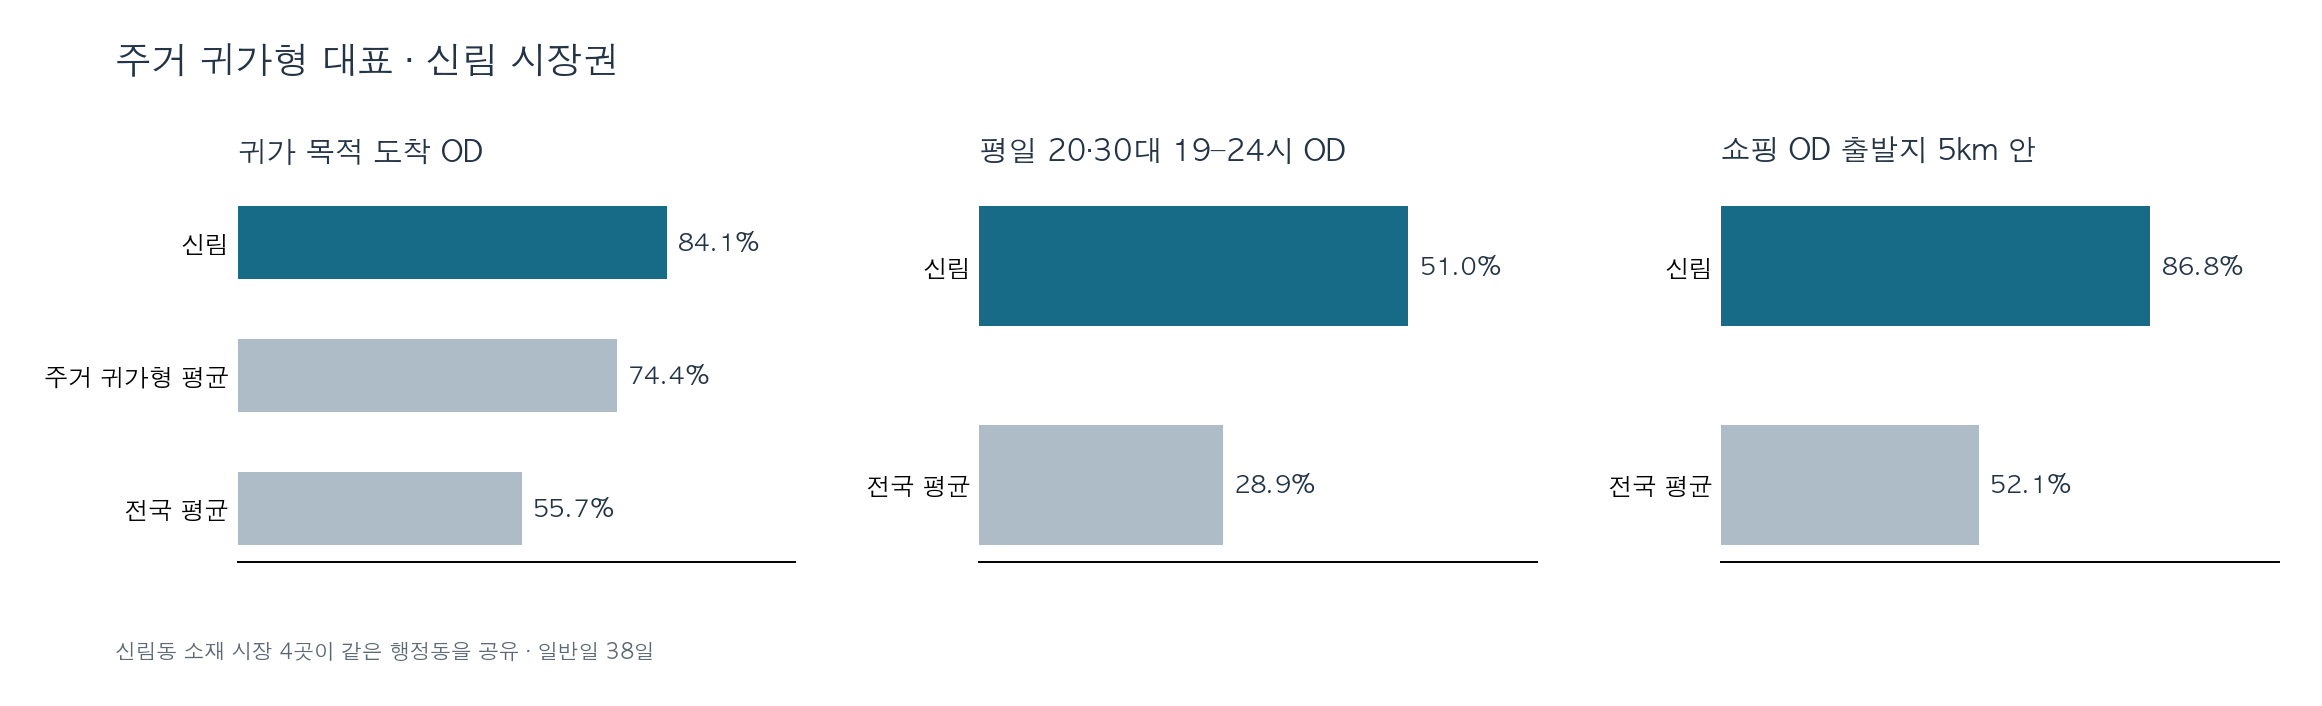

In [2]:
filename, title, panels, note = CASE_COMPARISONS[CASE]
comparison = pd.DataFrame([
    {"지표": metric, "비교 대상": name, "값": value, "단위": unit}
    for metric, names, values, unit in panels
    for name, value in zip(names, values)
])
display(comparison)
plot_case_comparison(CASE)
display(Image(filename=str(FIGS / filename)))

## 체류 구성

In [ ]:
stay = STAY
selected = stay.loc[stay["case"].eq(CASE),
                    ["metric", "case_share", "national_market_row_mean", "scope"]].copy()
selected[["case_share", "national_market_row_mean"]] *= 100
display(selected.rename(columns={"case_share":"사례 (%)",
                                  "national_market_row_mean":"전국 시장 행 평균 (%)"}))
plot_stay_case(CASE)
display(Image(filename=str(FIGS / STAY_CASES[CASE][0])))

## 시간·요일별 분포

,measure,daytype,정점 시각,시간별 구성비 (%)
133,20·30대 도착 OD,주말,21,9.5
147,20·30대 도착 OD,평일,19,14.5
152,20·30대 체류 STAY,주말,8,7.0
183,20·30대 체류 STAY,평일,23,8.6


,measure,day_of_week,요일별 구성비 (%),observed_days
28,20·30대 도착 OD,0,14.5,4
29,20·30대 도착 OD,1,14.6,5
30,20·30대 도착 OD,2,13.8,6
31,20·30대 도착 OD,3,14.5,5
32,20·30대 도착 OD,4,14.1,6
33,20·30대 도착 OD,5,14.1,6
34,20·30대 도착 OD,6,14.5,6
35,20·30대 체류 STAY,0,13.1,4
36,20·30대 체류 STAY,1,13.3,5
37,20·30대 체류 STAY,2,13.4,6


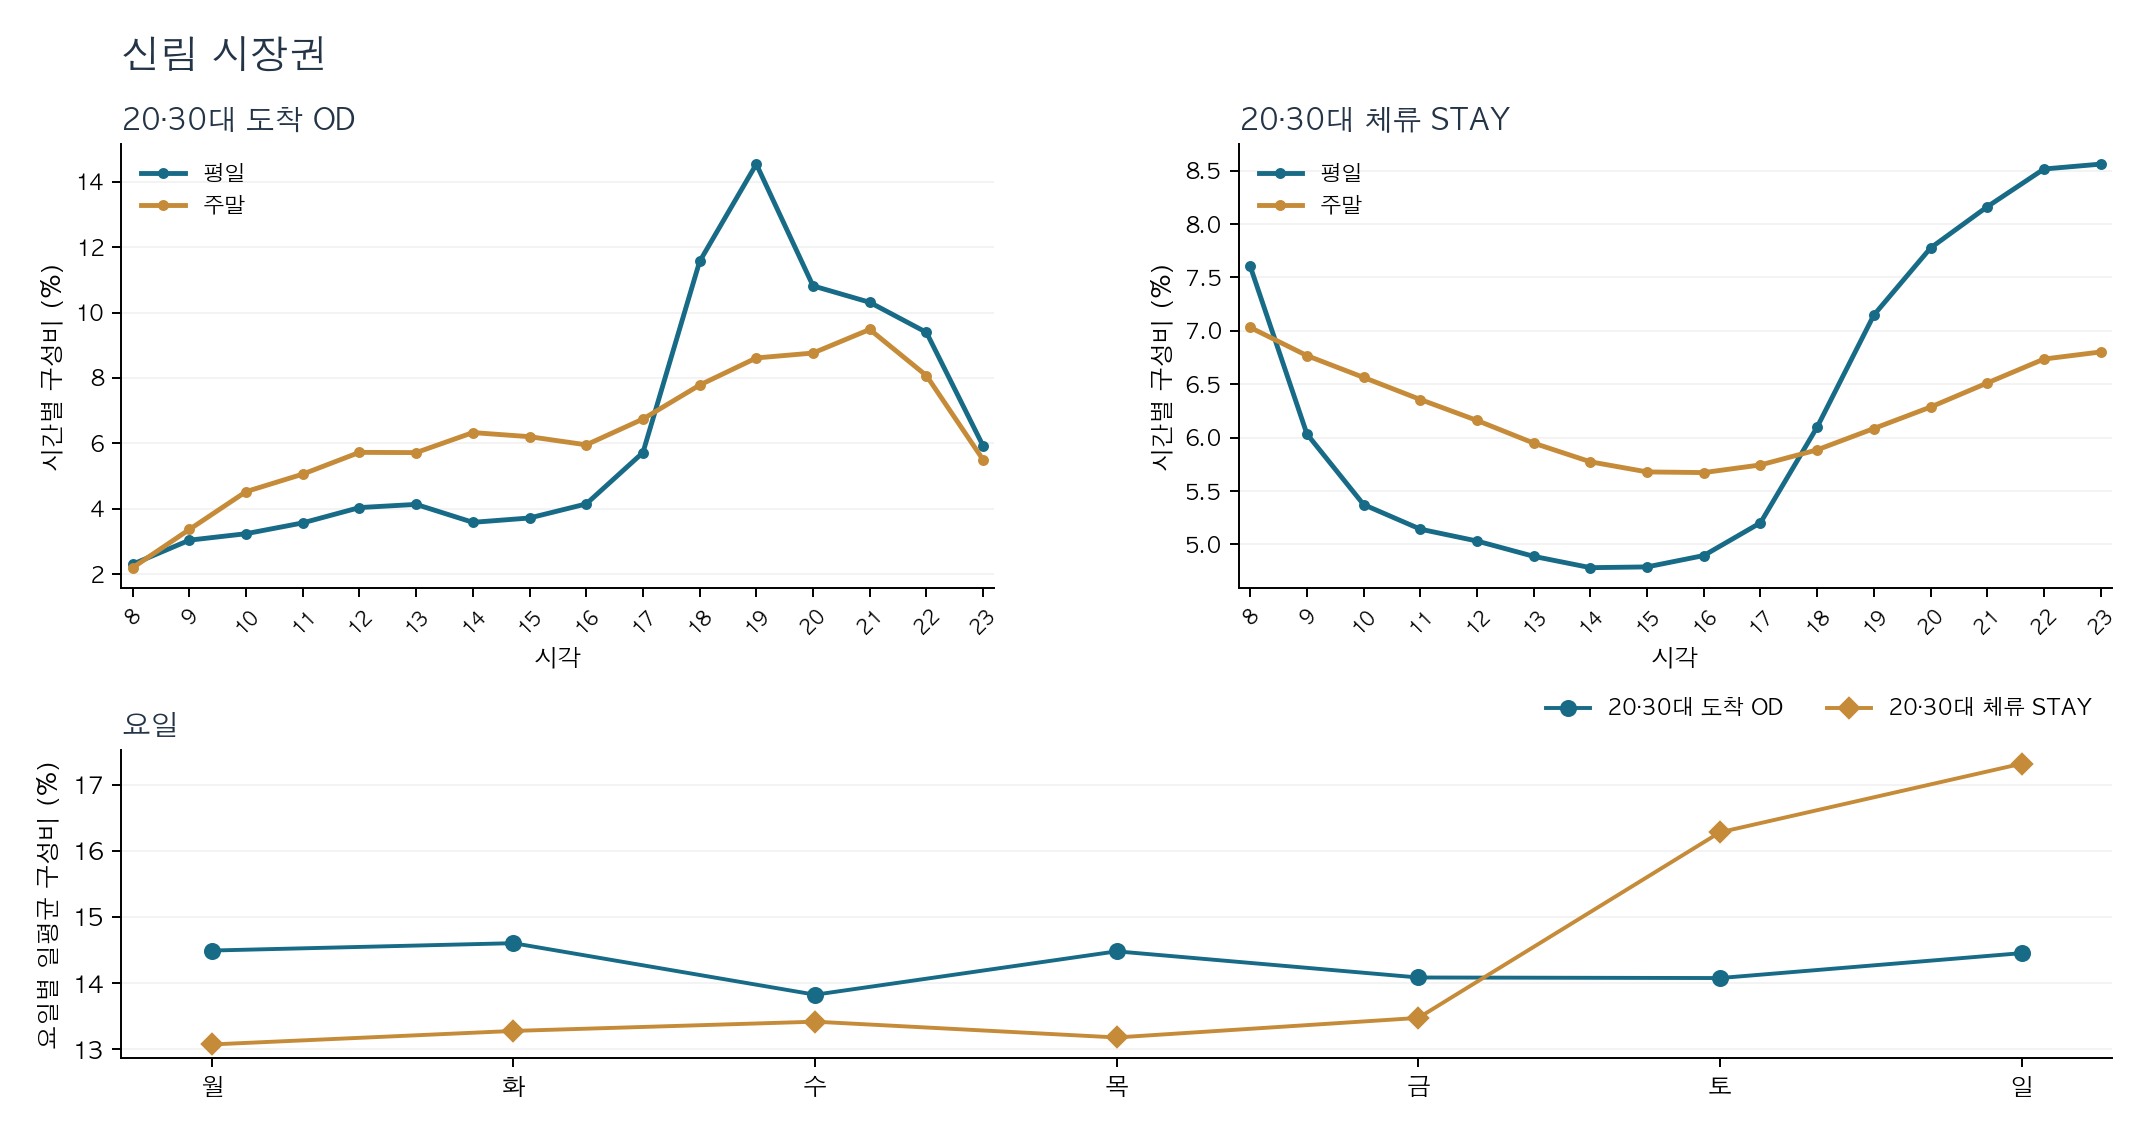

In [4]:
hourly = HOUR.loc[HOUR["case"].eq(CASE)].copy()
peaks = hourly.loc[hourly.groupby(["measure", "daytype"])["hour_share"].idxmax(),
                   ["measure", "daytype", "hour", "hour_share"]].copy()
peaks["hour_share"] = (peaks["hour_share"] * 100).round(1)
display(peaks.rename(columns={"hour":"정점 시각", "hour_share":"시간별 구성비 (%)"}))
weekday = WEEK.loc[WEEK["case"].eq(CASE)].copy()
weekday["요일별 구성비 (%)"] = weekday.groupby("measure")["daily_index"].transform(
    lambda values: values / values.sum() * 100
).round(1)
display(weekday[["measure", "day_of_week", "요일별 구성비 (%)", "observed_days"]])
plot_time_weekday(CASE)
display(Image(filename=str(FIGS / TIME_FIGURES[CASE])))

## 주변 조건

* 그림: 비공개 시설·공간 입력으로 작성한 저장 결과
* 재생성: 비공개 입력 경로 지정 시 가능

비공개 배후 후보·행정동 경계 입력이 없어 저장된 지도를 표시합니다.


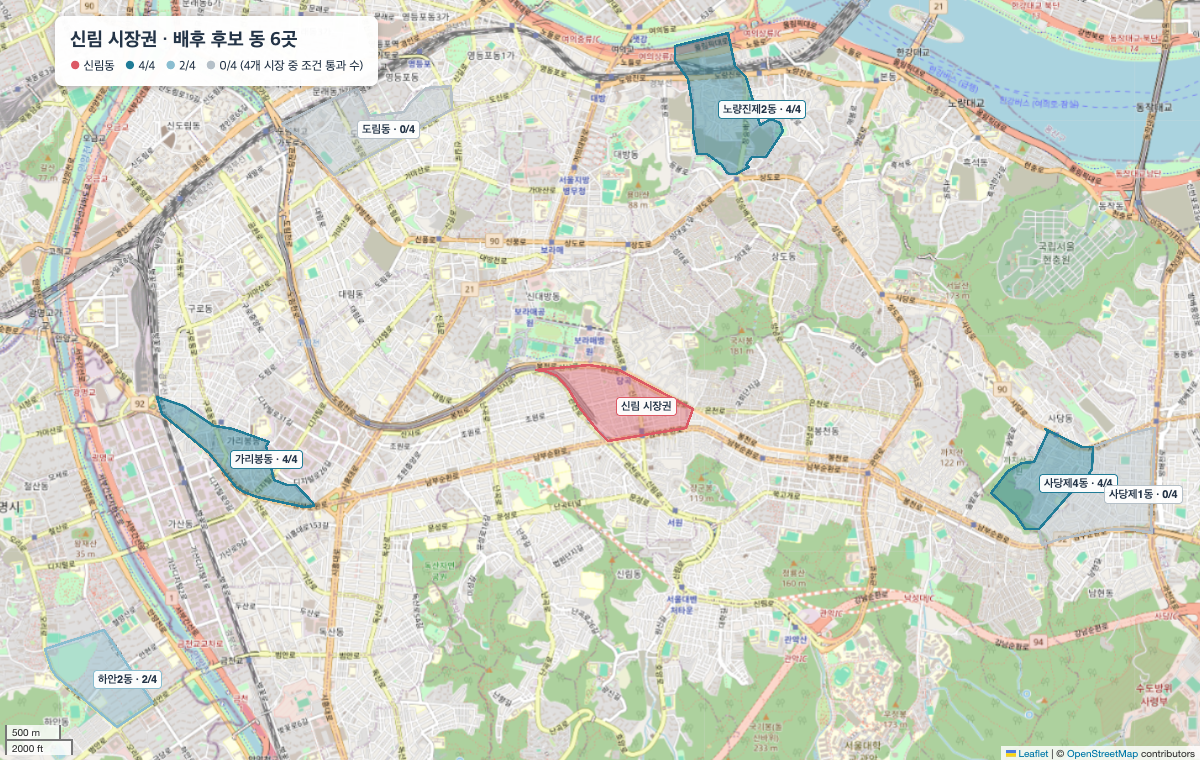

In [5]:
import os, json, tempfile
from plotting import sillim, render_map_png
source_paths = [os.environ.get(name) for name in
                ["BC_SILLIM_CANDIDATES", "BC_HDONG_BOUNDARIES", "BC_HDONG_CENTROIDS"]]
figure_path = Path("../figs") / "fig_v4_3b_sillim_hinterland.png"
if all(p and Path(p).exists() for p in source_paths):
    candidates = pd.read_csv(source_paths[0])
    boundaries = json.loads(Path(source_paths[1]).read_text())
    centroids = pd.read_csv(source_paths[2], dtype={"행정기관코드": str})
    with tempfile.TemporaryDirectory() as folder:
        map_html = sillim(candidates, boundaries, centroids, Path(folder))
        render_map_png(map_html, FIGS / "fig_v4_3b_sillim_hinterland.png", 1200, 760)
    figure_path = FIGS / "fig_v4_3b_sillim_hinterland.png"
else:
    print("비공개 배후 후보·행정동 경계 입력이 없어 저장된 지도를 표시합니다.")
display(Image(filename=str(figure_path)))

## 제안

* 방안: 평일 귀가 시간대 간편 먹거리·장보기 운영과 배후 동 안내 검토
* 상태: 시행·효과 미확인